<a href="https://colab.research.google.com/github/jessicamile94-star/crisis-mmd-multimodal-emergency-detection/blob/main/CrisisMMD_Multimodal_Jessica_Ballesteros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección multimodal de emergencias en redes sociales mediante texto e imágenes

## Introducción
Las redes sociales, especialmente Twitter/X, se han consolidado como fuentes de información en tiempo real durante situaciones de desastre y emergencia. Durante eventos como huracanes, terremotos e inundaciones, los ciudadanos publican de manera espontánea imágenes, reportes y solicitudes de ayuda que pueden ser de alto valor para los organismos de respuesta humanitaria. Sin embargo, el alto volumen de publicaciones irrelevantes, rumores y contenido fuera de contexto dificulta la identificación automática de información verdaderamente útil, generando una sobrecarga informacional que puede costar vidas.

Los enfoques monomodales —basados únicamente en texto o únicamente en imágenes— presentan limitaciones estructurales en precisión y generan tasas elevadas de falsos positivos. Un clasificador de texto puede confundir menciones coloquiales de palabras como "inundación" o "catástrofe" con reportes reales de emergencia; del mismo modo, un clasificador de imágenes puede activarse ante fotografías de accidentes ficticios, videojuegos o películas. Ambos errores pueden saturar los canales de atención de emergencia con alertas irrelevantes.
La fusión de ambas modalidades —texto e imagen— permite enriquecer la representación semántica de cada publicación y mitigar estos errores de clasificación. Una publicación cuyo texto describe daños estructurales y cuya imagen muestra edificios derrumbados proporciona evidencia convergente que un modelo unimodal no puede aprovechar.

Esta investigación propone el desarrollo y evaluación de un modelo multimodal sobre la configuración `informative` del dataset CrisisMMD. El modelo combina un codificador textual basado en TF-IDF y un codificador visual CLIP ViT-B/32 para clasificar publicaciones como informativas o no informativas. La evaluación se realiza mediante validación cruzada estratificada y una partición oficial de entrenamiento, validación y prueba.

1. Descarga de Dependencias necesarias

In [7]:
import os
import sys
import json
import time
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("Dispositivo:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Dispositivo: cuda
GPU: Tesla T4


2. Creacion de carpetas del proyecto

In [8]:
from pathlib import Path

ROOT = Path("/content/crisis-mmd-project")
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
CACHE_DIR = ARTIFACTS_DIR / "cache"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

for folder in [DATA_DIR, ARTIFACTS_DIR, CACHE_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Carpeta principal:", ROOT)
print("Datos:", DATA_DIR)
print("Artefactos:", ARTIFACTS_DIR)

Carpeta principal: /content/crisis-mmd-project
Datos: /content/crisis-mmd-project/data
Artefactos: /content/crisis-mmd-project/artifacts


3. Carga de datos de texto

In [9]:
from huggingface_hub import snapshot_download

HF_REPO = "QCRI/CrisisMMD"
HF_CONFIG = "informative"

snapshot_download(
    repo_id=HF_REPO,
    repo_type="dataset",
    local_dir=str(DATA_DIR),
    allow_patterns=["informative/*.json"],
)

print("Archivos descargados:")
for archivo in sorted((DATA_DIR / HF_CONFIG).glob("*.json")):
    print(archivo.name)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Archivos descargados:
dev.json
test.json
train.json


4. Estratificacion de datos

In [10]:
frames = []

for split_name in ["train", "dev", "test"]:
    file_path = DATA_DIR / "informative" / f"{split_name}.json"
    temp = pd.read_json(file_path)
    temp["official_split"] = split_name
    frames.append(temp)

df_full = pd.concat(frames, ignore_index=True)
sample_parts = []

for (split_name, label), group in df_full.groupby(
    ["official_split", "label"], observed=True
):
    n_sample = max(1, int(len(group) * 0.10))
    sample_parts.append(
        group.sample(n=n_sample, random_state=SEED)
    )

df = pd.concat(sample_parts, ignore_index=True)

print("Dataset completo:", df_full.shape)
print("Muestra estratificada:", df.shape)
print("\nDistribución por partición y clase:")
display(pd.crosstab(df["official_split"], df["label"]))

Dataset completo: (18082, 7)
Muestra estratificada: (1806, 7)

Distribución por partición y clase:


label,informative,not_informative
official_split,,
dev,140,83
test,137,86
train,834,526


In [11]:
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras filas:")
display(df.head(3))

print("\nValores nulos:")
display(df.isna().sum().to_frame("nulos"))

print("\nFilas duplicadas:")
print(df.duplicated().sum())

print("\nDistribución de clases:")
display(df["label"].value_counts())

Dimensiones: (1806, 7)

Columnas:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'label', 'official_split']

Primeras filas:


,event_name,tweet_id,image_id,tweet_text,image_path,label,official_split
0,hurricane_maria,927255483290877953,9.272555e+18,Gods blessings are seen in Puerto Rico everyda...,data_image/hurricane_maria/5_11_2017/927255483...,informative,dev
1,mexico_earthquake,910523988014534656,9.105240e+18,RT @thedailybeast: Images from Mexico City's d...,data_image/mexico_earthquake/20_9_2017/9105239...,informative,dev
2,hurricane_maria,912419664642367493,9.124197e+18,Tourists marvel at Hurricane Maria's wicked wa...,data_image/hurricane_maria/25_9_2017/912419664...,informative,dev



Valores nulos:


,nulos
event_name,0
tweet_id,0
image_id,0
tweet_text,0
image_path,0
label,0
official_split,0



Filas duplicadas:
0

Distribución de clases:


,count
label,
informative,1111
not_informative,695


## Exploratory Data Analysis (EDA)

El conjunto de datos utilizado corresponde a una muestra estratificada del 10 % de la categoria `informative` del dataset CrisisMMD. La muestra contiene **1.806 publicaciones de Twitter**, cada una asociada con un evento de desastre, un texto, una imagen y una etiqueta de clasificación.

El dataset contiene las siguientes variables:

- `event_name`: nombre del desastre natural.
- `tweet_id`: identificador de la publicación.
- `image_id`: identificador de la imagen.
- `tweet_text`: texto publicado en Twitter.
- `image_path`: ruta de la imagen asociada.
- `label`: clase objetivo.
- `official_split`: partición original del dataset (`train`, `dev` o `test`).

No se encontraron valores nulos en ninguna columna y tampoco se detectaron filas duplicadas. Esto indica que la muestra presenta una estructura completa para realizar el preprocesamiento y el entrenamiento del modelo.

La variable objetivo contiene dos clases:

- **Informative:** 1.111 publicaciones, equivalentes aproximadamente al **61,5 %**.
- **Not informative:** 695 publicaciones, equivalentes aproximadamente al **38,5 %**.

Por lo tanto, existe un desbalance moderado entre las clases. Aunque la diferencia no es extrema, se deben reportar métricas adicionales a la exactitud, como precisión, recall, F1-score, ROC-AUC y PR-AUC.

La muestra fue seleccionada de manera estratificada por partición oficial y etiqueta. Esto permite conservar aproximadamente la proporción original de clases en los conjuntos `train`, `dev` y `test`, evitando que la reducción del tamaño del dataset altere significativamente su distribución.

Desde el punto de vista multimodal, cada observación contiene dos fuentes de información complementarias: el texto de la publicación y una imagen asociada. Esta estructura permite comparar modelos unimodales, basados únicamente en texto o imágenes, con un modelo multimodal que combine ambas representaciones.

In [12]:
sample_image_paths = sorted(df["image_path"].unique())

print("Imágenes solicitadas:", len(sample_image_paths))

snapshot_download(
    repo_id=HF_REPO,
    repo_type="dataset",
    local_dir=str(DATA_DIR),
    allow_patterns=sample_image_paths,
)

print("Descarga de imágenes terminada.")

Imágenes solicitadas: 1806


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1806 files:   0%|          | 0/1806 [00:00<?, ?it/s]

Descarga de imágenes terminada.


In [13]:
from PIL import Image

def check_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

df["local_image_path"] = df["image_path"].apply(
    lambda p: DATA_DIR / p
)

df["image_exists"] = df["local_image_path"].apply(
    lambda p: p.exists()
)

df["image_valid"] = df["local_image_path"].apply(
    check_image
)

print("Imágenes existentes:")
print(df["image_exists"].value_counts())

print("\nImágenes válidas:")
print(df["image_valid"].value_counts())

print("\nImágenes faltantes:", (~df["image_exists"]).sum())
print("Imágenes inválidas:", (~df["image_valid"]).sum())

Imágenes existentes:
image_exists
True    1806
Name: count, dtype: int64

Imágenes válidas:
image_valid
True    1806
Name: count, dtype: int64

Imágenes faltantes: 0
Imágenes inválidas: 0


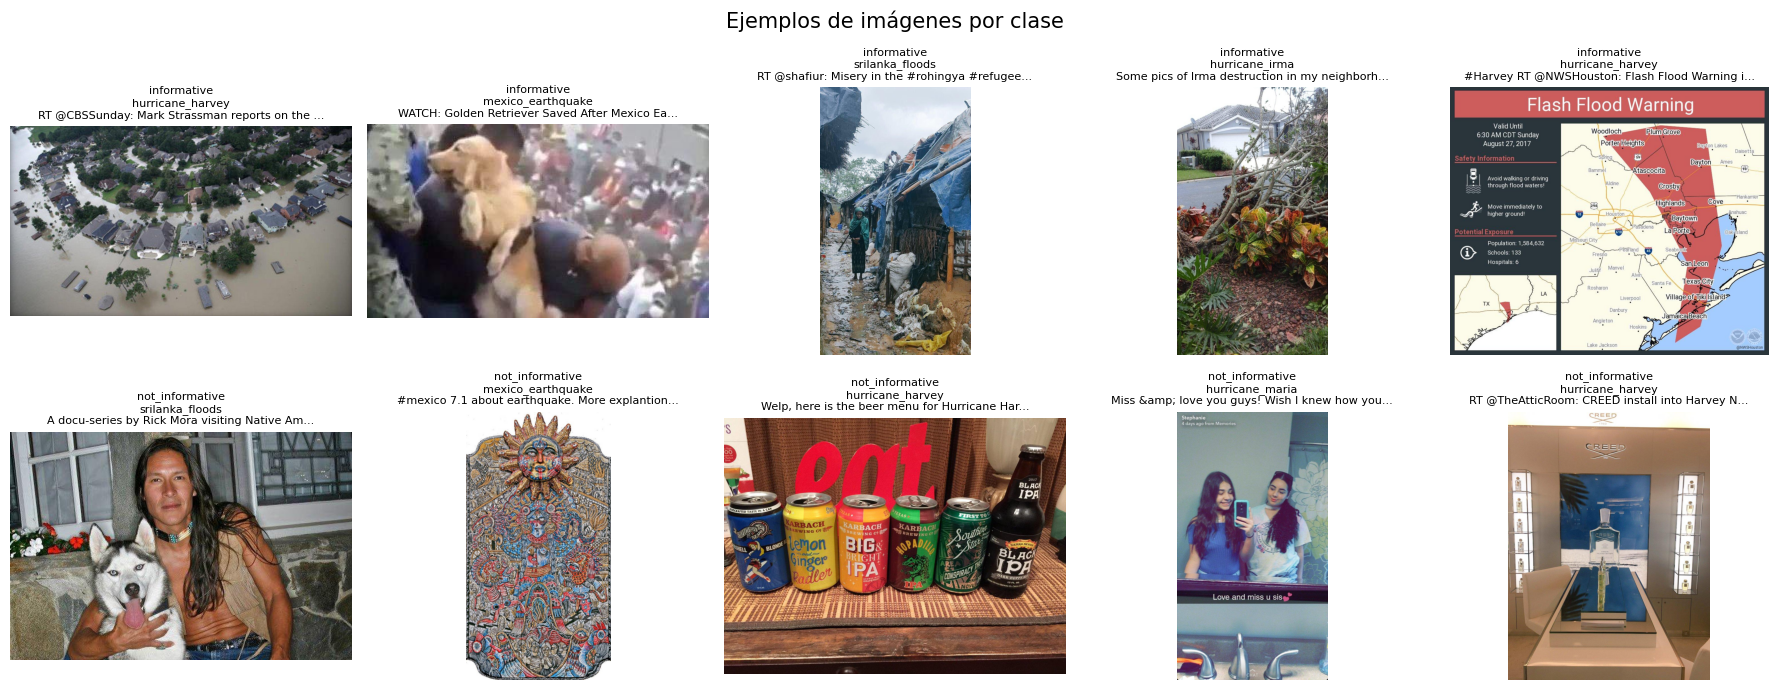

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for row_index, class_name in enumerate(["informative", "not_informative"]):
    examples = df[df["label"] == class_name].sample(
        n=5,
        random_state=SEED
    )

    for col_index, (_, record) in enumerate(examples.iterrows()):
        image = Image.open(record["local_image_path"]).convert("RGB")

        axes[row_index, col_index].imshow(image)
        axes[row_index, col_index].set_title(
            f"{class_name}\n{record['event_name']}\n"
            f"{record['tweet_text'][:45]}...",
            fontsize=8
        )
        axes[row_index, col_index].axis("off")

plt.suptitle("Ejemplos de imágenes por clase", fontsize=15)
plt.tight_layout()
plt.show()

Hallazgo :
Las publicaciones muestran daños, rescates, inundaciones.
Las no informativas muestran, memes, logos pero otras son imágenes relacionadas visualmente indirectamente.
La etiqueta no depende únicamente de la apariencia visual; también depende del texto y del contexto.

label,informative,not_informative
event_name,,
california_wildfires,109,48
hurricane_harvey,294,162
hurricane_irma,293,147
hurricane_maria,255,196
iraq_iran_earthquake,43,15
mexico_earthquake,86,44
srilanka_floods,31,83


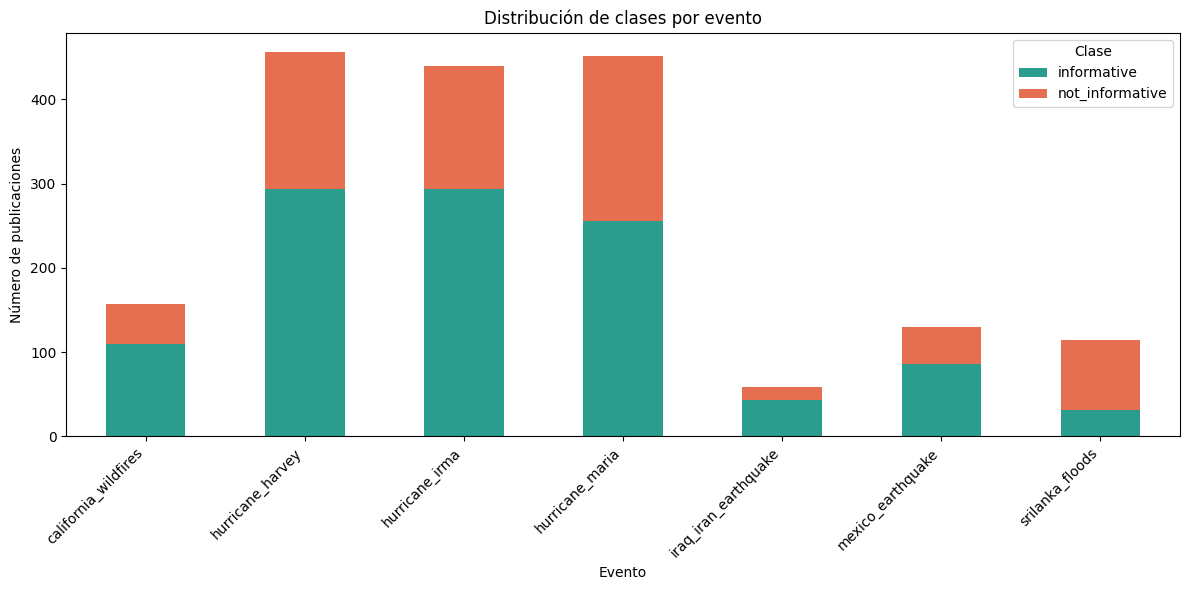

In [15]:
event_label_table = pd.crosstab(
    df["event_name"],
    df["label"]
)

display(event_label_table)

event_label_table.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#2a9d8f", "#e76f51"]
)

plt.title("Distribución de clases por evento")
plt.xlabel("Evento")
plt.ylabel("Número de publicaciones")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

### Distribución de clases por evento

La distribución de las etiquetas varía considerablemente entre los eventos. Mientras que `hurricane_harvey`, `hurricane_irma` y `hurricane_maria` tienen  principalmente publicaciones informativas, `srilanka_floods` presenta una mayor proporción de publicaciones no informativas.

Esta heterogeneidad indica que el modelo puede aprender patrones específicos de cada desastre y no necesariamente generalizar a eventos nuevos. Por este motivo, es importante realizar una evaluación temporal por evento y reportar métricas adicionales a la exactitud.

El evento `iraq_iran_earthquake` posee un número reducido de observaciones en la muestra, por lo que sus resultados deben interpretarse con cautela.

Por eso no debemos evaluar solamente con accuracy; también usaremos F1, recall, precisión y ROC-AUC.

Recall: detectar la mayor cantidad de emergencias.

Precisión: reducir falsas alarmas.

F1: equilibrar ambas.


ROC-AUC: evaluar la capacidad general de separación.

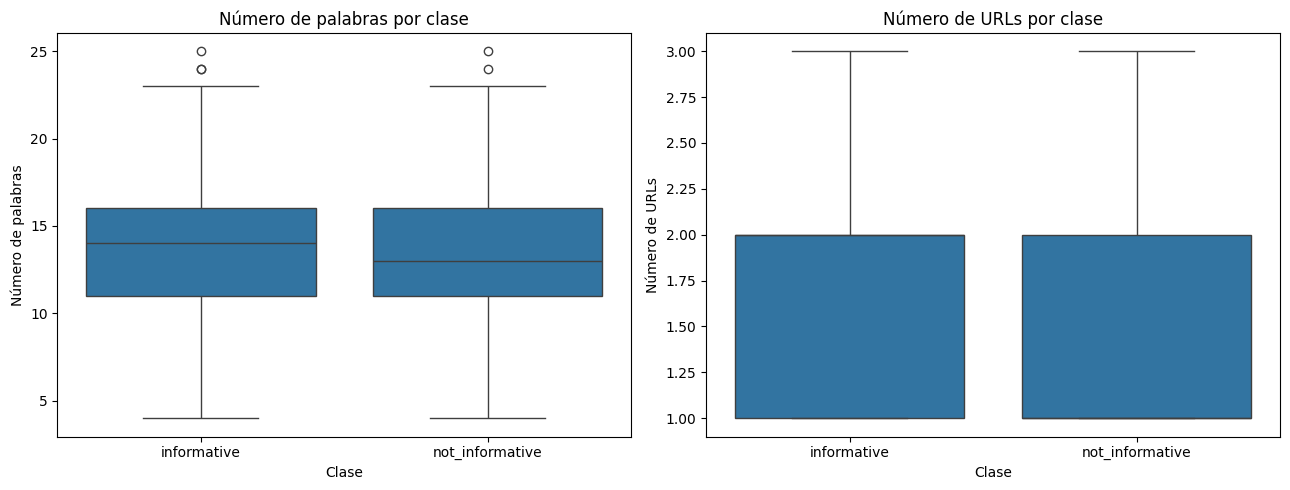

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="label",
    y="text_word_count",
    ax=axes[0]
)

axes[0].set_title("Número de palabras por clase")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Número de palabras")

sns.boxplot(
    data=df,
    x="label",
    y="url_count",
    ax=axes[1]
)

axes[1].set_title("Número de URLs por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Número de URLs")

plt.tight_layout()
plt.show()

### Conclusión del análisis textual

Las variables simples de longitud, cantidad de palabras y número de URLs presentan distribuciones muy similares entre las dos clases. Por lo tanto, estas características no son suficientes para diferenciar una publicación informativa de una no informativa.

Se requiere un método que represente el contenido semántico de los tweets. Para este proyecto se utilizará una representación Bag-of-Words/TF-IDF, complementada posteriormente con embeddings visuales obtenidos mediante CLIP.

 preprocesamiento del texto


In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Conservamos negaciones importantes
stopwords = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor", "never"
}

def clean_text(text):
    text = str(text).lower()

    # Eliminar retweets
    text = re.sub(r"^rt\s+", "", text)

    # Eliminar URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Eliminar menciones
    text = re.sub(r"@\w+", " ", text)

    # Convertir hashtags en palabras
    text = re.sub(r"#(\w+)", r"\1", text)

    # Mantener sólo letras
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Separar palabras
    words = text.split()

    # Eliminar conectores y palabras vacías
    words = [
        word for word in words
        if word not in stopwords
    ]

    return " ".join(words)

df["clean_text"] = df["tweet_text"].apply(clean_text)

display(
    df[["tweet_text", "clean_text"]].head(10)
)

,tweet_text,clean_text
0,Gods blessings are seen in Puerto Rico everyda...,gods blessings seen puerto rico everyday palm ...
1,RT @thedailybeast: Images from Mexico City's d...,images mexico city s devastating earthquake
2,Tourists marvel at Hurricane Maria's wicked wa...,tourists marvel hurricane maria s wicked waves...
3,#Chive Guy Fieri feeds BBQ to thousands of Cal...,chive guy fieri feeds bbq thousands california...
4,Celebrity Golf Tournament and Gala helps Hurri...,celebrity golf tournament gala helps hurricane...
5,Together we are stronger #StrongerTogether #Hu...,stronger strongertogether hurricanemaria help
6,Strategic Planning: Business Viability - Using...,strategic planning business viability using pu...
7,Image of the Week - Irma Churns Up Sediment in...,image week irma churns sediment florida keys v...
8,RT @ScottFisherFOX7: Scott Fisher Says: ¬ anot...,scott fisher says update hurricaneirma hurrica...
9,Hurricane Harvey floodwater 'flexed Earth's cr...,hurricane harvey floodwater flexed earth s crust


## Feature Extraction

Extracción de características textuales con TF-IDF

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer


train_mask = df["official_split"] == "train"
dev_mask = df["official_split"] == "dev"
test_mask = df["official_split"] == "test"

text_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=768,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    ))
])

X_train_text = text_pipeline.fit_transform(
    df.loc[train_mask, "clean_text"]
)

X_dev_text = text_pipeline.transform(
    df.loc[dev_mask, "clean_text"]
)

X_test_text = text_pipeline.transform(
    df.loc[test_mask, "clean_text"]
)

print("Train:", X_train_text.shape)
print("Dev:", X_dev_text.shape)
print("Test:", X_test_text.shape)

Train: (1360, 768)
Dev: (223, 768)
Test: (223, 768)


Extraccion de caracteristicas de Imagenes CLIP

Instalacion de CLIP ViT-B/32.  512 caracteristica

In [23]:
from transformers import CLIPProcessor, CLIPModel

CLIP_NAME = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)
clip_model = CLIPModel.from_pretrained(CLIP_NAME)

clip_model = clip_model.to(DEVICE)
clip_model.eval()

for parameter in clip_model.parameters():
    parameter.requires_grad = False

print("Modelo cargado:", CLIP_NAME)
print("Dispositivo:", DEVICE)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Modelo cargado: openai/clip-vit-base-patch32
Dispositivo: cuda


Prueba con una sola imagen

In [25]:
from PIL import Image
sample_path = df.iloc[0]["local_image_path"]
sample_image = Image.open(sample_path).convert("RGB")
inputs = clip_processor(
    images=sample_image,
    return_tensors="pt"
)
inputs = {
    key: value.to(DEVICE)
    for key, value in inputs.items()
}
with torch.no_grad():
    vision_outputs = clip_model.vision_model(
        pixel_values=inputs["pixel_values"]
    )
    image_embedding = clip_model.visual_projection(
        vision_outputs.pooler_output
    )
print("Dimensión del embedding:", image_embedding.shape)
print("Imagen utilizada:", sample_path)

Dimensión del embedding: torch.Size([1, 512])
Imagen utilizada: /content/crisis-mmd-project/data/data_image/hurricane_maria/5_11_2017/927255483290877953_0.jpg


Extraccion de caracteristicas de todas las imagenes

In [26]:
from tqdm.auto import tqdm

image_paths = df["local_image_path"].tolist()
image_embeddings = []

BATCH_SIZE = 32

with torch.inference_mode():
    for start in tqdm(
        range(0, len(image_paths), BATCH_SIZE),
        desc="Extrayendo características visuales"
    ):
        batch_paths = image_paths[start:start + BATCH_SIZE]

        batch_images = [
            Image.open(path).convert("RGB")
            for path in batch_paths
        ]

        batch_inputs = clip_processor(
            images=batch_images,
            return_tensors="pt"
        )

        pixel_values = batch_inputs["pixel_values"].to(DEVICE)

        vision_outputs = clip_model.vision_model(
            pixel_values=pixel_values
        )

        batch_embeddings = clip_model.visual_projection(
            vision_outputs.pooler_output
        )
        batch_embeddings = batch_embeddings / (
            batch_embeddings.norm(dim=-1, keepdim=True) + 1e-8
        )

        image_embeddings.append(
            batch_embeddings.cpu().numpy()
        )

X_image = np.concatenate(image_embeddings, axis=0)

print("Características visuales:", X_image.shape)

Extrayendo características visuales:   0%|          | 0/57 [00:00<?, ?it/s]

Características visuales: (1806, 512)


Fusion de texto e Imagenes

In [27]:
# Convertir las características de texto a matrices normales
X_train_text_dense = X_train_text.toarray()
X_dev_text_dense = X_dev_text.toarray()
X_test_text_dense = X_test_text.toarray()

# Seleccionar las imágenes correspondientes a cada partición
X_train_image = X_image[train_mask.values]
X_dev_image = X_image[dev_mask.values]
X_test_image = X_image[test_mask.values]

# Concatenar texto e imagen
X_train_multimodal = np.hstack([
    X_train_text_dense,
    X_train_image
])

X_dev_multimodal = np.hstack([
    X_dev_text_dense,
    X_dev_image
])

X_test_multimodal = np.hstack([
    X_test_text_dense,
    X_test_image
])

# Etiquetas numéricas
label_map = {
    "not_informative": 0,
    "informative": 1
}

y_train = df.loc[train_mask, "label"].map(label_map).to_numpy()
y_dev = df.loc[dev_mask, "label"].map(label_map).to_numpy()
y_test = df.loc[test_mask, "label"].map(label_map).to_numpy()

print("Train multimodal:", X_train_multimodal.shape)
print("Dev multimodal:", X_dev_multimodal.shape)
print("Test multimodal:", X_test_multimodal.shape)

Train multimodal: (1360, 1280)
Dev multimodal: (223, 1280)
Test multimodal: (223, 1280)


## Feature Selection

No se aplicó una técnica de selección de características adicional sobre las representaciones finales. Esta decisión se justifica porque el texto fue transformado mediante TF-IDF con un vocabulario limitado a 768 características y las imágenes fueron representadas mediante CLIP, un modelo de transferencia de aprendizaje que ya produce embeddings visuales compactos de 512 dimensiones.

Además, la primera capa del MLP aprende automáticamente una transformación de las 1.280 características de entrada. Por estas razones, se decidió conservar todas las características extraídas y evitar eliminar dimensiones importantes del embedding visual de CLIP.

## Clasificador MLP

In [28]:
class MultimodalMLP(nn.Module):

    def __init__(self, input_dim=1280, hidden_dim=512, dropout=0.3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


model = MultimodalMLP().to(DEVICE)

print(model)
print(
    "Parámetros entrenables:",
    sum(parameter.numel() for parameter in model.parameters())
)

MultimodalMLP(
  (network): Sequential(
    (0): Linear(in_features=1280, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=1, bias=True)
  )
)
Parámetros entrenables: 656385


preparar datos para PyTorch

In [29]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.tensor(X_train_multimodal, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

dev_dataset = TensorDataset(
    torch.tensor(X_dev_multimodal, dtype=torch.float32),
    torch.tensor(y_dev, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_multimodal, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Batches de entrenamiento:", len(train_loader))
print("Batches de validación:", len(dev_loader))
print("Batches de prueba:", len(test_loader))

Batches de entrenamiento: 22
Batches de validación: 4
Batches de prueba: 4


Entrenamiento Inicial

In [30]:
from sklearn.metrics import roc_auc_score

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

history = {
    "train_loss": [],
    "dev_loss": [],
    "dev_auc": []
}

best_auc = 0.0
best_model_state = None

EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
    model.eval()
    total_dev_loss = 0.0
    dev_logits = []
    dev_labels = []

    with torch.no_grad():
        for X_batch, y_batch in dev_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_dev_loss += loss.item()
            dev_logits.extend(logits.cpu().numpy())
            dev_labels.extend(y_batch.cpu().numpy())

    train_loss = total_train_loss / len(train_loader)
    dev_loss = total_dev_loss / len(dev_loader)

    dev_probabilities = torch.sigmoid(
        torch.tensor(dev_logits)
    ).numpy()

    dev_auc = roc_auc_score(
        dev_labels,
        dev_probabilities
    )

    history["train_loss"].append(train_loss)
    history["dev_loss"].append(dev_loss)
    history["dev_auc"].append(dev_auc)

    if dev_auc > best_auc:
        best_auc = dev_auc
        best_model_state = model.state_dict()

    print(
        f"Época {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Dev loss: {dev_loss:.4f} | "
        f"Dev ROC-AUC: {dev_auc:.4f}"
    )

Época 01/20 | Train loss: 0.6389 | Dev loss: 0.6084 | Dev ROC-AUC: 0.8193
Época 02/20 | Train loss: 0.5159 | Dev loss: 0.5312 | Dev ROC-AUC: 0.8155
Época 03/20 | Train loss: 0.4277 | Dev loss: 0.5209 | Dev ROC-AUC: 0.8196
Época 04/20 | Train loss: 0.3659 | Dev loss: 0.5427 | Dev ROC-AUC: 0.8206
Época 05/20 | Train loss: 0.3304 | Dev loss: 0.5522 | Dev ROC-AUC: 0.8133
Época 06/20 | Train loss: 0.2816 | Dev loss: 0.5807 | Dev ROC-AUC: 0.8133
Época 07/20 | Train loss: 0.2416 | Dev loss: 0.6262 | Dev ROC-AUC: 0.8005
Época 08/20 | Train loss: 0.2084 | Dev loss: 0.6593 | Dev ROC-AUC: 0.7909
Época 09/20 | Train loss: 0.1882 | Dev loss: 0.6968 | Dev ROC-AUC: 0.7902
Época 10/20 | Train loss: 0.1642 | Dev loss: 0.7398 | Dev ROC-AUC: 0.7824
Época 11/20 | Train loss: 0.1436 | Dev loss: 0.7718 | Dev ROC-AUC: 0.7772
Época 12/20 | Train loss: 0.1265 | Dev loss: 0.8036 | Dev ROC-AUC: 0.7812
Época 13/20 | Train loss: 0.1111 | Dev loss: 0.8587 | Dev ROC-AUC: 0.7786
Época 14/20 | Train loss: 0.0959 | Dev

Podemos ver un sobreajuste por que el Train Loss bajo continuamente   , el dev Loss   bajo y comenzo a subir indica que el modelo empezó a memorizar train y perdió capacidad de generalizar.

Train loss
0.6389 → 0.0503
Esto significa que el modelo cada vez memoriza mejor los datos de entrenamiento.

Dev loss
Primero bajó:
0.6084 → 0.5209
Pero después comenzó a subir:
0.5209 → 1.0822
Eso indica que el modelo empezó a memorizar train y perdió capacidad de generalizar.

Dev ROC-AUC
El mejor resultado fue aproximadamente:
Época 04: ROC-AUC = 0.8206

S e procede a volver a entrenar guardando correctamente el mejor modelo.



In [31]:
import copy


model = MultimodalMLP().to(DEVICE)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

history = {
    "train_loss": [],
    "dev_loss": [],
    "dev_auc": []
}

best_auc = -float("inf")
best_epoch = 0
best_model_state = None
patience = 3
epochs_without_improvement = 0
EPOCHS = 20

for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    model.eval()
    total_dev_loss = 0.0
    dev_logits = []
    dev_labels = []

    with torch.no_grad():
        for X_batch, y_batch in dev_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_dev_loss += loss.item()
            dev_logits.extend(logits.cpu().numpy())
            dev_labels.extend(y_batch.cpu().numpy())

    train_loss = total_train_loss / len(train_loader)
    dev_loss = total_dev_loss / len(dev_loader)

    dev_probabilities = torch.sigmoid(
        torch.tensor(dev_logits)
    ).numpy()

    dev_auc = roc_auc_score(
        dev_labels,
        dev_probabilities
    )

    history["train_loss"].append(train_loss)
    history["dev_loss"].append(dev_loss)
    history["dev_auc"].append(dev_auc)

    print(
        f"Época {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Dev loss: {dev_loss:.4f} | "
        f"Dev ROC-AUC: {dev_auc:.4f}"
    )

    if dev_auc > best_auc:
        best_auc = dev_auc
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping activado.")
        break

# Restaurar el mejor modelo
model.load_state_dict(best_model_state)

print(f"Mejor época: {best_epoch}")
print(f"Mejor Dev ROC-AUC: {best_auc:.4f}")

Época 01/20 | Train loss: 0.6314 | Dev loss: 0.6115 | Dev ROC-AUC: 0.8136
Época 02/20 | Train loss: 0.5188 | Dev loss: 0.5261 | Dev ROC-AUC: 0.8140
Época 03/20 | Train loss: 0.4270 | Dev loss: 0.5150 | Dev ROC-AUC: 0.8188
Época 04/20 | Train loss: 0.3658 | Dev loss: 0.5275 | Dev ROC-AUC: 0.8215
Época 05/20 | Train loss: 0.3129 | Dev loss: 0.5710 | Dev ROC-AUC: 0.8178
Época 06/20 | Train loss: 0.2740 | Dev loss: 0.5932 | Dev ROC-AUC: 0.8073
Época 07/20 | Train loss: 0.2410 | Dev loss: 0.6179 | Dev ROC-AUC: 0.7944
Early stopping activado.
Mejor época: 4
Mejor Dev ROC-AUC: 0.8215


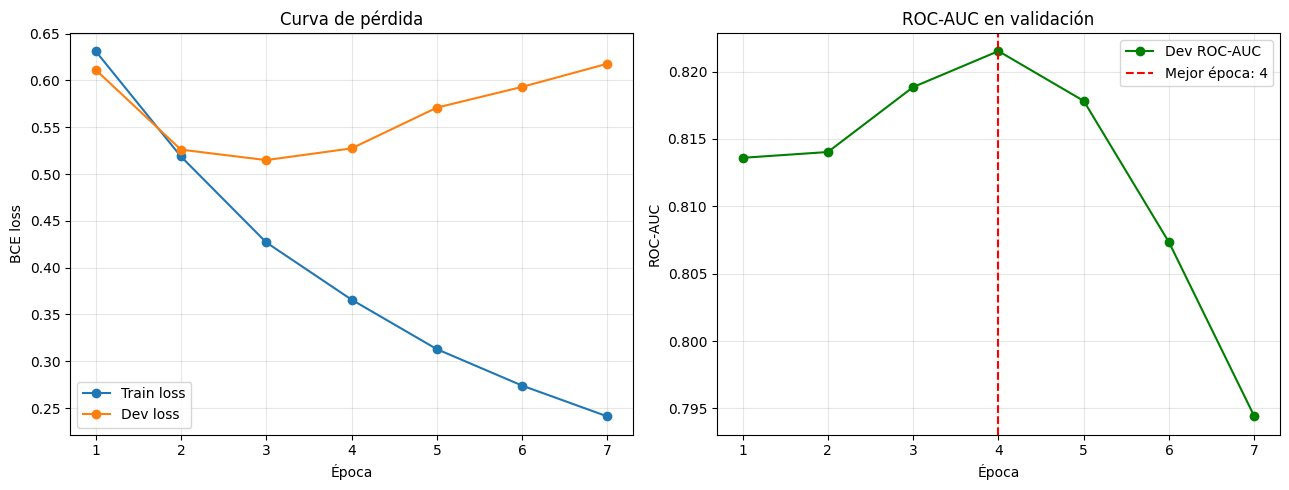

In [32]:
epochs_used = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de pérdida
axes[0].plot(
    epochs_used,
    history["train_loss"],
    marker="o",
    label="Train loss"
)

axes[0].plot(
    epochs_used,
    history["dev_loss"],
    marker="o",
    label="Dev loss"
)

axes[0].set_title("Curva de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("BCE loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Curva ROC-AUC
axes[1].plot(
    epochs_used,
    history["dev_auc"],
    marker="o",
    color="green",
    label="Dev ROC-AUC"
)

axes[1].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Mejor época: {best_epoch}"
)

axes[1].set_title("ROC-AUC en validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Análisis de la curva de aprendizaje**


El modelo aprende correctamente durante las primeras épocas. La pérdida de entrenamiento disminuye de 0.6314 a 0.2410, lo que indica que el modelo mejora sus predicciones sobre los datos de entrenamiento.

La pérdida de validación disminuye hasta la época 3, donde alcanza aproximadamente 0.5150. Después comienza a aumentar, mientras la pérdida de entrenamiento continúa disminuyendo. Este comportamiento indica que el modelo empieza a memorizar los datos de entrenamiento y pierde capacidad de generalización.

El mejor resultado se obtuvo en la época 4, con un ROC-AUC de 0.8215 en el conjunto de validación. Después de esta época, el ROC-AUC disminuyó progresivamente.

Por esta razón, se utilizó early stopping. El entrenamiento se detuvo en la época 7 después de tres épocas sin mejora. Finalmente, se conservaron los pesos correspondientes a la época 4, que fue la mejor configuración encontrada durante este entrenamiento inicial.

 Repeated Stratified K-Fold

In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score
from torch.utils.data import TensorDataset, DataLoader

def train_one_fold(X_fold_train, y_fold_train,
                   X_fold_val, y_fold_val,
                   hidden_dim=512,
                   dropout=0.3,
                   learning_rate=0.001,
                   weight_decay=0.0001,
                   batch_size=64,
                   epochs=10):

    fold_model = MultimodalMLP(
        input_dim=1280,
        hidden_dim=hidden_dim,
        dropout=dropout
    ).to(DEVICE)

    fold_optimizer = torch.optim.Adam(
        fold_model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    fold_criterion = nn.BCEWithLogitsLoss()

    fold_dataset = TensorDataset(
        torch.tensor(X_fold_train, dtype=torch.float32),
        torch.tensor(y_fold_train, dtype=torch.float32)
    )

    fold_loader = DataLoader(
        fold_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    for _ in range(epochs):
        fold_model.train()

        for X_batch, y_batch in fold_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            fold_optimizer.zero_grad()

            logits = fold_model(X_batch)
            loss = fold_criterion(logits, y_batch)

            loss.backward()
            fold_optimizer.step()

    fold_model.eval()

    with torch.no_grad():
        X_val_tensor = torch.tensor(
            X_fold_val,
            dtype=torch.float32
        ).to(DEVICE)

        val_logits = fold_model(X_val_tensor)
        val_probabilities = torch.sigmoid(val_logits)
        val_probabilities = val_probabilities.cpu().numpy()

    return roc_auc_score(y_fold_val, val_probabilities)


cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=SEED
)

baseline_cv_scores = []

for fold_number, (train_indices, val_indices) in enumerate(
    cv.split(X_train_multimodal, y_train),
    start=1
):

    score = train_one_fold(
        X_train_multimodal[train_indices],
        y_train[train_indices],
        X_train_multimodal[val_indices],
        y_train[val_indices]
    )

    baseline_cv_scores.append(score)

    print(
        f"Fold {fold_number}/10 - ROC-AUC: {score:.4f}"
    )

print("\nResultado CV modelo base:")
print("Media:", np.mean(baseline_cv_scores))
print("Desviación estándar:", np.std(baseline_cv_scores))

Fold 1/10 - ROC-AUC: 0.7737
Fold 2/10 - ROC-AUC: 0.8355
Fold 3/10 - ROC-AUC: 0.8040
Fold 4/10 - ROC-AUC: 0.8160
Fold 5/10 - ROC-AUC: 0.8187
Fold 6/10 - ROC-AUC: 0.8273
Fold 7/10 - ROC-AUC: 0.8172
Fold 8/10 - ROC-AUC: 0.8261
Fold 9/10 - ROC-AUC: 0.7696
Fold 10/10 - ROC-AUC: 0.8044

Resultado CV modelo base:
Media: 0.8092500207262543
Desviación estándar: 0.020940526489126036



La desviación estándar baja indica que el modelo no depende demasiado de una única división de los datos. Las diferencias entre folds son normales porque cada fold contiene publicaciones diferentes y puede tener eventos o ejemplos más difíciles.



**optimización de hiperparámetros con Optuna**

In [35]:
import optuna

# Guardar las mismas divisiones para comparar todos los trials
cv_splits = list(
    cv.split(X_train_multimodal, y_train)
)

def objective(trial):

    params = {
        "hidden_dim": trial.suggest_categorical(
            "hidden_dim",
            [128, 256, 512]
        ),
        "dropout": trial.suggest_float(
            "dropout",
            0.1,
            0.6
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            1e-4,
            5e-3,
            log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay",
            1e-6,
            1e-2,
            log=True
        ),
        "batch_size": trial.suggest_categorical(
            "batch_size",
            [32, 64, 128]
        )
    }

    scores = []

    for train_indices, val_indices in cv_splits:

        score = train_one_fold(
            X_train_multimodal[train_indices],
            y_train[train_indices],
            X_train_multimodal[val_indices],
            y_train[val_indices],
            hidden_dim=params["hidden_dim"],
            dropout=params["dropout"],
            learning_rate=params["learning_rate"],
            weight_decay=params["weight_decay"],
            batch_size=params["batch_size"],
            epochs=10
        )

        scores.append(score)

    mean_score = np.mean(scores)

    return mean_score


study = optuna.create_study(
    direction="maximize",
    study_name="crisismmd_mlp_optimization"
)

study.optimize(
    objective,
    n_trials=8,
    show_progress_bar=True
)

print("Mejor ROC-AUC:", study.best_value)
print("Mejores hiperparámetros:")

for parameter, value in study.best_params.items():
    print(f"{parameter}: {value}")

[I 2026-11-21 03:00:13,151] A new study created in memory with name: crisismmd_mlp_optimization


  0%|          | 0/8 [00:00<?, ?it/s]

[I 2026-11-21 03:00:26,045] Trial 0 finished with value: 0.8154441086974883 and parameters: {'hidden_dim': 512, 'dropout': 0.32437190251858394, 'learning_rate': 0.0006101498820064082, 'weight_decay': 0.00016208215310139926, 'batch_size': 32}. Best is trial 0 with value: 0.8154441086974883.
[I 2026-11-21 03:00:32,919] Trial 1 finished with value: 0.8363877496201051 and parameters: {'hidden_dim': 256, 'dropout': 0.3188053657757305, 'learning_rate': 0.00010249107146984724, 'weight_decay': 2.4889488176344657e-06, 'batch_size': 64}. Best is trial 1 with value: 0.8363877496201051.
[I 2026-11-21 03:00:40,829] Trial 2 finished with value: 0.7980335646052745 and parameters: {'hidden_dim': 512, 'dropout': 0.19555775287339897, 'learning_rate': 0.0011727647754435847, 'weight_decay': 1.0905038043623981e-05, 'batch_size': 64}. Best is trial 1 with value: 0.8363877496201051.
[I 2026-11-21 03:00:54,178] Trial 3 finished with value: 0.8346973947406069 and parameters: {'hidden_dim': 128, 'dropout': 0.42

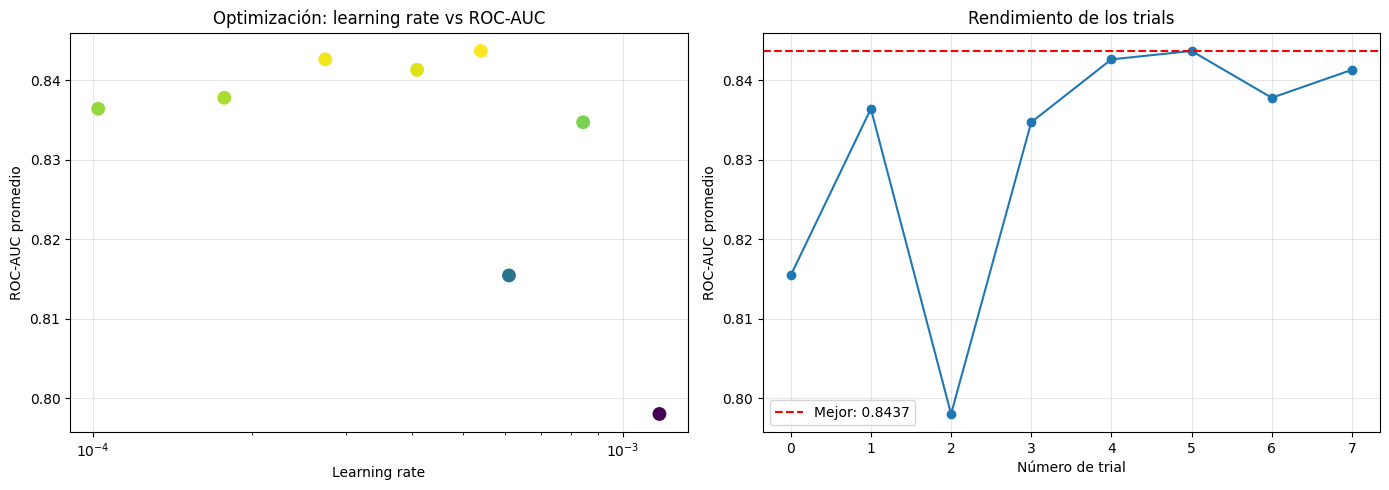

In [36]:
trials_df = study.trials_dataframe()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Relación entre learning rate y ROC-AUC
axes[0].scatter(
    trials_df["params_learning_rate"],
    trials_df["value"],
    s=80,
    c=trials_df["value"],
    cmap="viridis"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Learning rate")
axes[0].set_ylabel("ROC-AUC promedio")
axes[0].set_title("Optimización: learning rate vs ROC-AUC")
axes[0].grid(alpha=0.3)

# Rendimiento de cada trial
axes[1].plot(
    trials_df["number"],
    trials_df["value"],
    marker="o"
)

axes[1].axhline(
    study.best_value,
    color="red",
    linestyle="--",
    label=f"Mejor: {study.best_value:.4f}"
)

axes[1].set_xlabel("Número de trial")
axes[1].set_ylabel("ROC-AUC promedio")
axes[1].set_title("Rendimiento de los trials")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

La gráfica muestra que el mejor resultado se obtuvo en el Trial 5, con un ROC-AUC promedio de 0.8437. La configuración utilizó un learning rate cercano a 0.00054.

Los resultados sugieren que valores moderados del learning rate, aproximadamente entre 0.0002 y 0.0006, producen un mejor rendimiento. En cambio, un valor más alto, cercano a 0.0012, obtuvo un resultado inferior.

El rendimiento no aumenta de manera completamente lineal porque también depende de la combinación con el dropout, el tamaño de la capa oculta, el weight_decay y el tamaño del batch. Por tanto, la optimización permite encontrar una combinación equilibrada de hiperparámetros.

La configuración optimizada mejoró frente al modelo base:

Modelo base: 0.8093
Modelo optimizado: 0.8437
Mejora: 0.0344 ROC-AUC

entrenamiento del modelo con los mejores hiperparámetros

In [37]:
best_params = study.best_params

print("Hiperparámetros seleccionados:")
for name, value in best_params.items():
    print(f"{name}: {value}")

Hiperparámetros seleccionados:
hidden_dim: 512
dropout: 0.35478384900725646
learning_rate: 0.0005400992417174273
weight_decay: 0.0025476979617308866
batch_size: 128


In [38]:
def train_final_model(params, epochs=20, patience=3):

    final_model = MultimodalMLP(
        input_dim=1280,
        hidden_dim=params["hidden_dim"],
        dropout=params["dropout"]
    ).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        final_model.parameters(),
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"]
    )

    final_history = {
        "train_loss": [],
        "dev_loss": [],
        "dev_auc": []
    }

    best_auc = -float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):

        final_model.train()
        total_train_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            logits = final_model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()

        final_model.eval()
        total_dev_loss = 0.0
        dev_logits = []
        dev_labels = []

        with torch.no_grad():
            for X_batch, y_batch in dev_loader:

                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                logits = final_model(X_batch)
                loss = criterion(logits, y_batch)

                total_dev_loss += loss.item()
                dev_logits.extend(logits.cpu().numpy())
                dev_labels.extend(y_batch.cpu().numpy())

        train_loss = total_train_loss / len(train_loader)
        dev_loss = total_dev_loss / len(dev_loader)

        dev_probabilities = torch.sigmoid(
            torch.tensor(dev_logits)
        ).numpy()

        dev_auc = roc_auc_score(
            dev_labels,
            dev_probabilities
        )

        final_history["train_loss"].append(train_loss)
        final_history["dev_loss"].append(dev_loss)
        final_history["dev_auc"].append(dev_auc)

        print(
            f"Época {epoch + 1:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Dev loss: {dev_loss:.4f} | "
            f"Dev ROC-AUC: {dev_auc:.4f}"
        )

        if dev_auc > best_auc:
            best_auc = dev_auc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(
                final_model.state_dict()
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping activado.")
            break

    final_model.load_state_dict(best_state)

    print(f"\nMejor época: {best_epoch}")
    print(f"Mejor Dev ROC-AUC: {best_auc:.4f}")

    return final_model, final_history, best_epoch


optimized_model, optimized_history, optimized_best_epoch = (
    train_final_model(best_params)
)

Época 01/20 | Train loss: 0.6617 | Dev loss: 0.6443 | Dev ROC-AUC: 0.8153
Época 02/20 | Train loss: 0.5934 | Dev loss: 0.6087 | Dev ROC-AUC: 0.8165
Época 03/20 | Train loss: 0.5328 | Dev loss: 0.5671 | Dev ROC-AUC: 0.8186
Época 04/20 | Train loss: 0.4880 | Dev loss: 0.5326 | Dev ROC-AUC: 0.8206
Época 05/20 | Train loss: 0.4555 | Dev loss: 0.5248 | Dev ROC-AUC: 0.8260
Época 06/20 | Train loss: 0.4253 | Dev loss: 0.5155 | Dev ROC-AUC: 0.8268
Época 07/20 | Train loss: 0.4070 | Dev loss: 0.5110 | Dev ROC-AUC: 0.8263
Época 08/20 | Train loss: 0.3844 | Dev loss: 0.5162 | Dev ROC-AUC: 0.8272
Época 09/20 | Train loss: 0.3716 | Dev loss: 0.5142 | Dev ROC-AUC: 0.8268
Época 10/20 | Train loss: 0.3536 | Dev loss: 0.5217 | Dev ROC-AUC: 0.8252
Época 11/20 | Train loss: 0.3527 | Dev loss: 0.5192 | Dev ROC-AUC: 0.8246
Early stopping activado.

Mejor época: 8
Mejor Dev ROC-AUC: 0.8272


Podemos observar que la mejor epoca es la 8

Mejor ROC-AUC en validación: 0.8272


El modelo base obtuvo: 0.8215


Mejora en dev: aproximadamente 0.0057
Aunque Optuna obtuvo un promedio de 0.8437 en repeated k-fold, el resultado en dev fue 0.8272.


 Esto es normal porque:

El CV usa múltiples divisiones de train.
dev es un conjunto específico diferente.
El rendimiento puede variar dependiendo de los ejemplos y eventos presentes.
El modelo conservó los pesos de la época 8.

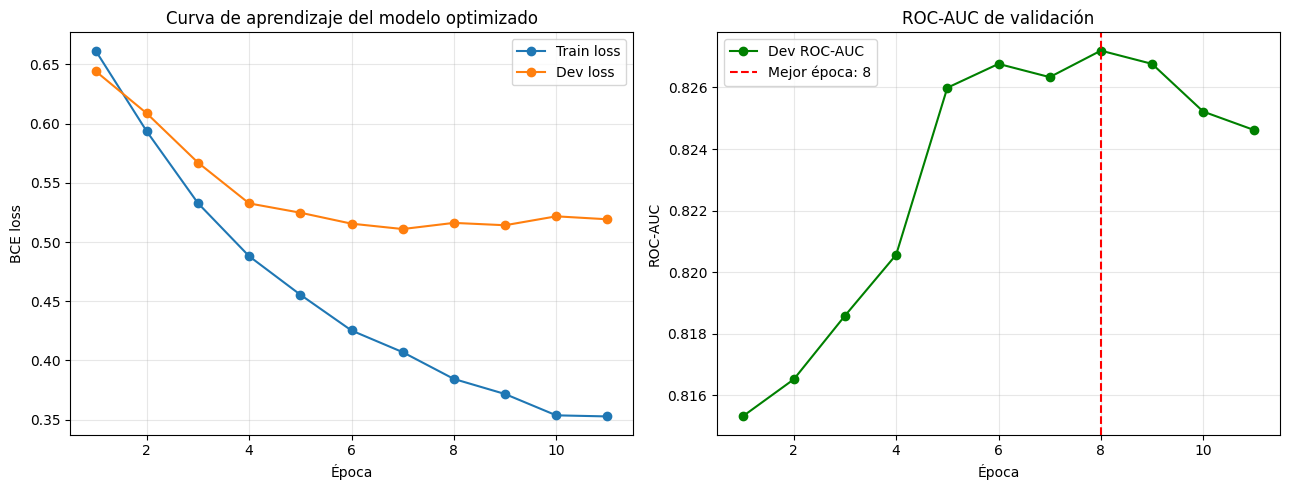

In [39]:
epochs_optimized = range(
    1,
    len(optimized_history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pérdida
axes[0].plot(
    epochs_optimized,
    optimized_history["train_loss"],
    marker="o",
    label="Train loss"
)

axes[0].plot(
    epochs_optimized,
    optimized_history["dev_loss"],
    marker="o",
    label="Dev loss"
)

axes[0].set_title("Curva de aprendizaje del modelo optimizado")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("BCE loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ROC-AUC
axes[1].plot(
    epochs_optimized,
    optimized_history["dev_auc"],
    marker="o",
    color="green",
    label="Dev ROC-AUC"
)

axes[1].axvline(
    optimized_best_epoch,
    color="red",
    linestyle="--",
    label=f"Mejor época: {optimized_best_epoch}"
)

axes[1].set_title("ROC-AUC de validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Análisis de la curva de aprendizaje**


La pérdida de entrenamiento disminuye progresivamente, lo que indica que el modelo aprende cada vez mejor los datos de entrenamiento. La pérdida de validación también disminuye al inicio y alcanza su valor mínimo aproximadamente en la época 7.

A partir de la época 8, la pérdida de validación comienza a estabilizarse y posteriormente aumenta ligeramente, mientras la pérdida de entrenamiento continúa descendiendo. Esto evidencia un inicio de sobreajuste.

El mejor resultado se obtuvo en la época 8, con un ROC-AUC de validación de 0.8272. Por este motivo, se conservaron los pesos de esa época. El early stopping detuvo el entrenamiento en la época 11 porque no hubo una mejora suficiente durante tres épocas consecutivas.

En general, el modelo optimizado presenta un aprendizaje más estable y alcanza un rendimiento ligeramente superior al modelo base.

**Comparación entre dos técnicas diferentes**

Red neuronal MLP con PyTorch.

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import wilcoxon

logistic_scores = []
mlp_scores = []

for fold_number, (train_indices, val_indices) in enumerate(
    cv_splits,
    start=1
):

    X_fold_train = X_train_multimodal[train_indices]
    X_fold_val = X_train_multimodal[val_indices]

    y_fold_train = y_train[train_indices]
    y_fold_val = y_train[val_indices]

    # Técnica 1: Regresión logística dentro de un pipeline
    logistic_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=SEED
        ))
    ])

    logistic_pipeline.fit(
        X_fold_train,
        y_fold_train
    )

    logistic_probabilities = logistic_pipeline.predict_proba(
        X_fold_val
    )[:, 1]

    logistic_auc = roc_auc_score(
        y_fold_val,
        logistic_probabilities
    )

    logistic_scores.append(logistic_auc)

    # Técnica 2: Red neuronal MLP optimizada
    mlp_auc = train_one_fold(
        X_fold_train,
        y_fold_train,
        X_fold_val,
        y_fold_val,
        hidden_dim=best_params["hidden_dim"],
        dropout=best_params["dropout"],
        learning_rate=best_params["learning_rate"],
        weight_decay=best_params["weight_decay"],
        batch_size=best_params["batch_size"],
        epochs=10
    )

    mlp_scores.append(mlp_auc)

    print(
        f"Fold {fold_number}/10 | "
        f"Logística: {logistic_auc:.4f} | "
        f"MLP: {mlp_auc:.4f}"
    )

logistic_scores = np.array(logistic_scores)
mlp_scores = np.array(mlp_scores)

# Comparación estadística pareada
wilcoxon_result = wilcoxon(
    mlp_scores,
    logistic_scores,
    alternative="two-sided"
)

comparison_table = pd.DataFrame({
    "Técnica": [
        "Regresión logística",
        "MLP multimodal"
    ],
    "Media ROC-AUC": [
        logistic_scores.mean(),
        mlp_scores.mean()
    ],
    "Desviación estándar": [
        logistic_scores.std(),
        mlp_scores.std()
    ]
})

display(comparison_table.round(4))

print("Estadístico de Wilcoxon:", wilcoxon_result.statistic)
print("Valor p:", wilcoxon_result.pvalue)

if wilcoxon_result.pvalue < 0.05:
    print("La diferencia es estadísticamente significativa.")
else:
    print("La diferencia no es estadísticamente significativa.")

Fold 1/10 | Logística: 0.7364 | MLP: 0.7941
Fold 2/10 | Logística: 0.7483 | MLP: 0.8818
Fold 3/10 | Logística: 0.7352 | MLP: 0.8285
Fold 4/10 | Logística: 0.7766 | MLP: 0.8514
Fold 5/10 | Logística: 0.7302 | MLP: 0.8680
Fold 6/10 | Logística: 0.7607 | MLP: 0.8642
Fold 7/10 | Logística: 0.7437 | MLP: 0.8412
Fold 8/10 | Logística: 0.7576 | MLP: 0.8559
Fold 9/10 | Logística: 0.7308 | MLP: 0.8088
Fold 10/10 | Logística: 0.7156 | MLP: 0.8416


,Técnica,Media ROC-AUC,Desviación estándar
0,Regresión logística,0.7435,0.0169
1,MLP multimodal,0.8435,0.0257


Estadístico de Wilcoxon: 0.0
Valor p: 0.001953125
La diferencia es estadísticamente significativa.


Regresión logística	0.7435	0.0169


MLP multimodal	0.8435	0.0257


El MLP supera a la regresión logística en aproximadamente:


0.8435 - 0.7435 = 0.1000 ROC-AUC


Prueba de Wilcoxon

Valor p = 0.001953125
Como: p < 0.05 se rechaza la hipótesis nula. La diferencia entre ambos modelos es estadísticamente significativa.

**visualización t-SNE**

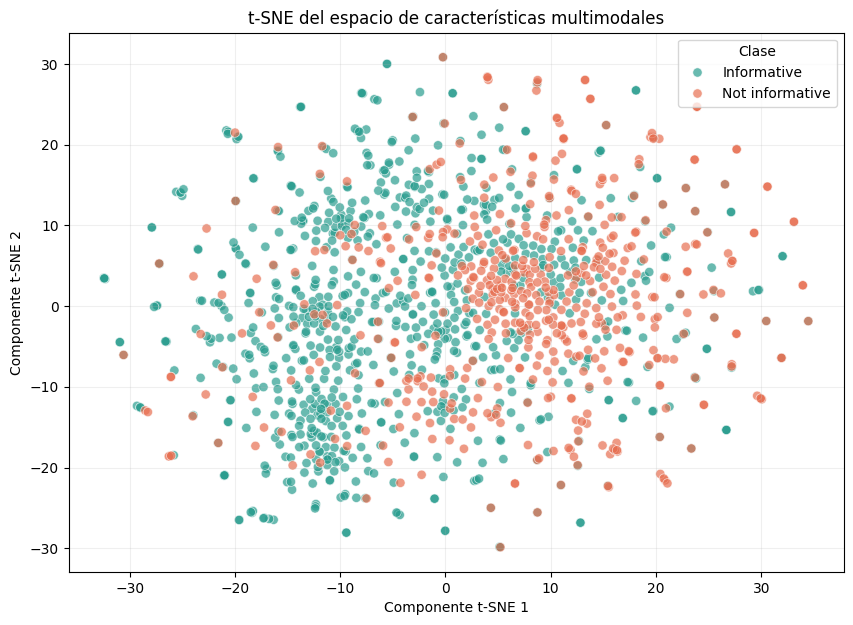

In [41]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler


X_tsne_source = X_train_multimodal
y_tsne_source = y_train


X_tsne_scaled = StandardScaler().fit_transform(
    X_tsne_source
)


tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=SEED
)

X_tsne = tsne_model.fit_transform(
    X_tsne_scaled
)

tsne_df = pd.DataFrame({
    "TSNE_1": X_tsne[:, 0],
    "TSNE_2": X_tsne[:, 1],
    "Clase": np.where(
        y_tsne_source == 1,
        "Informative",
        "Not informative"
    )
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x="TSNE_1",
    y="TSNE_2",
    hue="Clase",
    palette={
        "Informative": "#2a9d8f",
        "Not informative": "#e76f51"
    },
    alpha=0.7,
    s=45
)

plt.title("t-SNE del espacio de características multimodales")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.legend(title="Clase")
plt.grid(alpha=0.2)
plt.show()

La gráfica muestra que existe cierta estructura en las características multimodales, pero las clases no están completamente separadas.

Se observan algunas zonas donde predominan las publicaciones informativas y otras donde aparecen más publicaciones no informativas. Sin embargo, también existe bastante superposición entre ambos colores.

Esto significa que:

El texto y la imagen contienen información útil.
Las clases no son completamente separables de forma simple.
Algunas publicaciones son ambiguas y pueden pertenecer visualmente a ambas regiones.
Una separación perfecta no es esperable.


# Evaluación final en test

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

optimized_model.eval()

final_logits = []
final_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(DEVICE)

        logits = optimized_model(X_batch)

        final_logits.extend(
            logits.cpu().numpy()
        )

        final_labels.extend(
            y_batch.numpy()
        )

final_logits = np.array(final_logits)
final_labels = np.array(final_labels)

final_probabilities = 1 / (
    1 + np.exp(-final_logits)
)

final_predictions = (
    final_probabilities >= 0.5
).astype(int)

final_results = {
    "Accuracy": accuracy_score(
        final_labels,
        final_predictions
    ),
    "Precision": precision_score(
        final_labels,
        final_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        final_labels,
        final_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        final_labels,
        final_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        final_labels,
        final_probabilities
    ),
    "PR-AUC": average_precision_score(
        final_labels,
        final_probabilities
    )
}

display(
    pd.DataFrame(
        final_results.items(),
        columns=["Métrica", "Valor"]
    ).round(4)
)

print("Matriz de confusión:")
print(
    confusion_matrix(
        final_labels,
        final_predictions
    )
)

,Métrica,Valor
0,Accuracy,0.7578
1,Precision,0.7785
2,Recall,0.8467
3,F1-score,0.8112
4,ROC-AUC,0.8411
5,PR-AUC,0.8982


Matriz de confusión:
[[ 53  33]
 [ 21 116]]


53 publicaciones no informativas fueron clasificadas correctamente.


33 fueron falsas alarmas.


21 publicaciones informativas no fueron detectadas.


116 publicaciones informativas fueron detectadas correctamente.


El recall de 84,67 % es especialmente importante porque el sistema detecta la mayoría de las publicaciones informativas. El F1-score de 81,12 % muestra un equilibrio adecuado entre detectar emergencias y reducir falsas alarmas.

El modelo obtuvo un ROC-AUC de 0.8411, lo que indica una buena capacidad para separar publicaciones informativas y no informativas en eventos no utilizados durante la optimización. El resultado es coherente con el ROC-AUC promedio de validación cruzada obtenido con Optuna, que fue aproximadamente 0.8437.

In [47]:
results_comparison = pd.DataFrame({
    "Modelo": [
        "MLP base",
        "MLP optimizado",
        "Regresión logística"
    ],
    "ROC-AUC CV promedio": [
        np.mean(baseline_cv_scores),
        np.mean(mlp_scores),
        np.mean(logistic_scores)
    ],
    "ROC-AUC CV desviación": [
        np.std(baseline_cv_scores),
        np.std(mlp_scores),
        np.std(logistic_scores)
    ]
})

display(
    results_comparison.round(4)
)

,Modelo,ROC-AUC CV promedio,ROC-AUC CV desviación
0,MLP base,0.8093,0.0209
1,MLP optimizado,0.8435,0.0257
2,Regresión logística,0.7435,0.0169


### Comparación de modelos

El MLP optimizado obtuvo el mejor rendimiento promedio en validación cruzada, con un ROC-AUC de 0.8435, superando al MLP base, que alcanzó 0.8093. Esto representa una mejora de aproximadamente 0.0342 puntos de ROC-AUC.

La regresión logística obtuvo un ROC-AUC promedio de 0.7435, inferior a ambos modelos neuronales. Este resultado sugiere que la red neuronal puede capturar relaciones no lineales entre las características textuales y visuales, mientras que la regresión logística está limitada a relaciones lineales.

La variabilidad entre folds fue moderada, lo que indica que los modelos presentan un comportamiento relativamente estable ante diferentes particiones de los datos.


## Referencias

[1] F. Alam, F. Ofli, M. Imran, and T. A. Awan, “CrisisMMD: Multimodal Twitter datasets from natural disasters,” in *Proceedings of the International AAAI Conference on Web and Social Media*, vol. 14, 2020, pp. 465–473.

[2] A. Radford et al., “Learning transferable visual models from natural language supervision,” in *Proceedings of the 38th International Conference on Machine Learning*, vol. 139, 2021, pp. 8748–8763.

[3] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, “Optuna: A next-generation hyperparameter optimization framework,” in *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2019, pp. 2623–2631.

[4] F. Pedregosa et al., “Scikit-learn: Machine learning in Python,” *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[5] A. Paszke et al., “PyTorch: An imperative style, high-performance deep learning library,” in *Advances in Neural Information Processing Systems*, vol. 32, 2019.

[6] L. van der Maaten and G. Hinton, “Visualizing data using t-SNE,” *Journal of Machine Learning Research*, vol. 9, pp. 2579–2605, 2008.

[7] Hugging Face, “Transformers documentation,” 2026. [Online]. Available: https://huggingface.co/docs/transformers

[8] PyTorch Foundation, “PyTorch documentation,” 2026. [Online]. Available: https://pytorch.org/docs/stable/

## Prompts utilizados como apoyo

Durante la elaboración del notebook se utilizaron los siguientes prompts como apoyo para comprender conceptos, estructurar el código y analizar los resultados:

1. ¿Cómo construir un proyecto multimodal para clasificar publicaciones de Twitter usando texto e imágenes?

2. ¿Cómo trabajar con el dataset CrisisMMD desde Hugging Face?

3. ¿Cómo crear una muestra estratificada manteniendo la proporción de clases?

4. ¿Cómo realizar un análisis exploratorio de datos para un dataset con texto e imágenes?

5. ¿Cómo limpiar tweets eliminando URLs, menciones, retweets y stopwords?

6. ¿Cómo conservar palabras de negación importantes como “no” y “not” durante la limpieza de texto?

7. ¿Cómo utilizar TF-IDF para convertir tweets en características numéricas?

8. ¿Cómo construir un `Pipeline` de scikit-learn para aplicar TF-IDF sin filtración de información?

9. ¿Cómo extraer características visuales usando CLIP ViT-B/32?

10. ¿Cómo procesar imágenes por batches?

11. ¿Cómo verificar la existencia y validez de imágenes descargadas?

12. ¿Cómo combinar características textuales de 768 dimensiones con embeddings visuales de 512 dimensiones?

13. ¿Cómo construir una red neuronal MLP multimodal en PyTorch?

14. ¿Cómo utilizar `TensorDataset` y `DataLoader` para entrenar una red neuronal?

15. ¿Cómo detectar y corregir sobreajuste mediante curvas de aprendizaje?

16. ¿Cómo implementar early stopping guardando los pesos de la mejor época?

17. ¿Cómo aplicar repeated stratified k-fold cross-validation a un modelo de clasificación?

18. ¿Cómo optimizar hiperparámetros de una red neuronal usando Optuna?

19. ¿Cómo visualizar la relación entre un hiperparámetro y el ROC-AUC?

20. ¿Cómo comparar una regresión logística con una red neuronal usando las mismas particiones?

21. ¿Cómo aplicar la prueba estadística de Wilcoxon sobre resultados pareados de validación cruzada?

22. ¿Cómo visualizar características multimodales mediante t-SNE usando el label como color?

23. ¿Cómo interpretar accuracy, precision, recall, F1-score, ROC-AUC y PR-AUC?

24. ¿Cómo interpretar una matriz de confusión en un problema de detección de emergencias?

25. ¿Cómo redactar un análisis académico de los resultados de un modelo multimodal?

26. ¿Cómo organizar referencias bibliográficas en formato IEEE?

La asistencia de inteligencia artificial se utilizó como apoyo técnico y educativo. La selección del dataset, el diseño experimental, la interpretación de los resultados y las conclusiones fueron revisados y adaptados para este proyecto.

## Conclusiones

1. El modelo multimodal logró combinar texto e imagenes de publicaciones de CrisisMMD. El texto fue representado mediante TF-IDF y las imágenes mediante embeddings de CLIP ViT-B/32.

2. La representación conjunta produjo 1.280 características por publicación: 768 características textuales y 512 visuales. Esta combinación permitió que el modelo utilizara simultáneamente el contenido escrito y la evidencia visual.

3. La optimización de hiperparámetros mejoró el rendimiento del MLP. El ROC-AUC promedio pasó de 0.8093 en el modelo base a 0.8435 en el modelo optimizado.

4. La red neuronal MLP superó a la regresión logística. La regresión logística obtuvo un ROC-AUC promedio de 0.7435, mientras que el MLP alcanzó 0.8435.

5. La prueba de Wilcoxon obtuvo un valor p de 0.00195. Como este valor es < que 0.05, la diferencia es estadísticamente significativa.

6. El recall elevado es importante para este problema porque indica que el modelo detecta la mayoría de las publicaciones informativas. Sin embargo, todavía se produjeron falsos positivos.

7. La curva de aprendizaje mostró que el modelo comienza a sobreajustarse después de varias épocas. El uso de dropout, weight decay y early stopping ayudó a conservar la mejor versión del modelo.

8. La visualización t-SNE mostró cierta estructura entre las clases, aunque también existe una importante superposición.


## Limitaciones y trabajo futuro

El análisis inicial utilizó una muestra estratificada del 10 % del dataset para reducir el tiempo de ejecución en Google Colab. Como trabajo futuro, se recomienda repetir el entrenamiento final utilizando todo el dataset disponible.

Además, el modelo utiliza embeddings CLIP congelados y no realiza fine-tuning sobre las imágenes de CrisisMMD. También sería posible utilizar modelos de lenguaje más avanzados, como BERT o RoBERTa, para mejorar la representación textual.

